<a href="https://colab.research.google.com/github/ElBaron-27/UACJ_Ruben/blob/main/PracticaRegresionLinealMultiple_Ruben_Uribe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Rubén Alejandro Uribe Rodríguez
*   Matrícula: 271774

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

#Cargar el dataset de advertising
df = pd.read_csv('/content/drive/MyDrive/MIAAD UACJ/advertising.csv')

print(df.head())
# Descripción estadística del dataset
print("\nDescripción estadística del dataset:")
print(df.describe())

# Comprobamos si hay valores nulos
print("\nComprobando valores nulos:")
print(df.isnull().sum())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

Descripción estadística del dataset:
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149.750000   22.900000   25.750000   16.000000
75%    218.825000   36.525000   45.100000   19.050000
max    296.400000   49.600000  114.000000   27.000000

Comprobando valores nulos:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

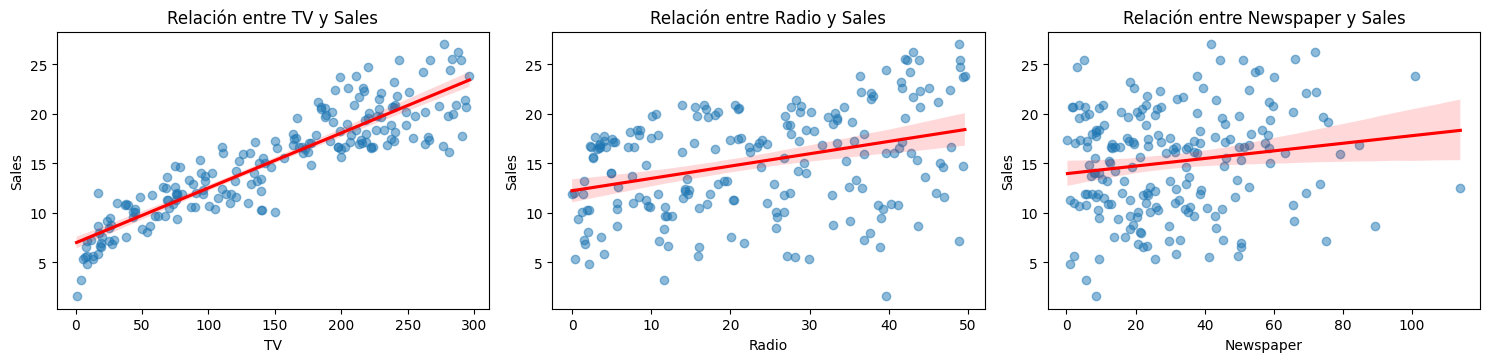

In [22]:
# Gráficos de dispersión

plt.figure(figsize=(15, 10))

for i, column in enumerate(df.columns[:-1]):
    plt.subplot(3, 3, i+1)

    sns.regplot(
        x=df[column],
        y=df['Sales'],
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'}
    )

    plt.title(f"Relación entre {column} y Sales")
    plt.xlabel(column)
    plt.ylabel("Sales")

plt.tight_layout()
plt.show()




**TV vs. Sales:** Se observa una relación positiva fuerte entre la inversión en publicidad televisiva y las ventas. La línea de regresión presenta una pendiente ascendente pronunciada y los puntos se concentran relativamente cerca de ella, lo que sugiere que TV tiene una alta capacidad explicativa de las ventas de manera individual. Sin embargo, se aprecia una ligera curvatura en la distribución de los datos, lo que podría indicar que la relación no es completamente lineal.

**Radio vs. Sales:** Se identifica una relación positiva, aunque menos pronunciada que en TV. La línea de regresión presenta una pendiente ascendente moderada, pero los puntos muestran una dispersión considerable a su alrededor. Esto indica que, aunque existe una tendencia de aumento en las ventas conforme crece la inversión en Radio, la relación lineal individual es menos fuerte y presenta mayor variabilidad.

**Newspaper vs. Sales:** La relación entre la inversión en periódicos y las ventas es positiva, pero muy débil. Aunque la línea de regresión muestra una ligera pendiente ascendente, los puntos están ampliamente dispersos.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

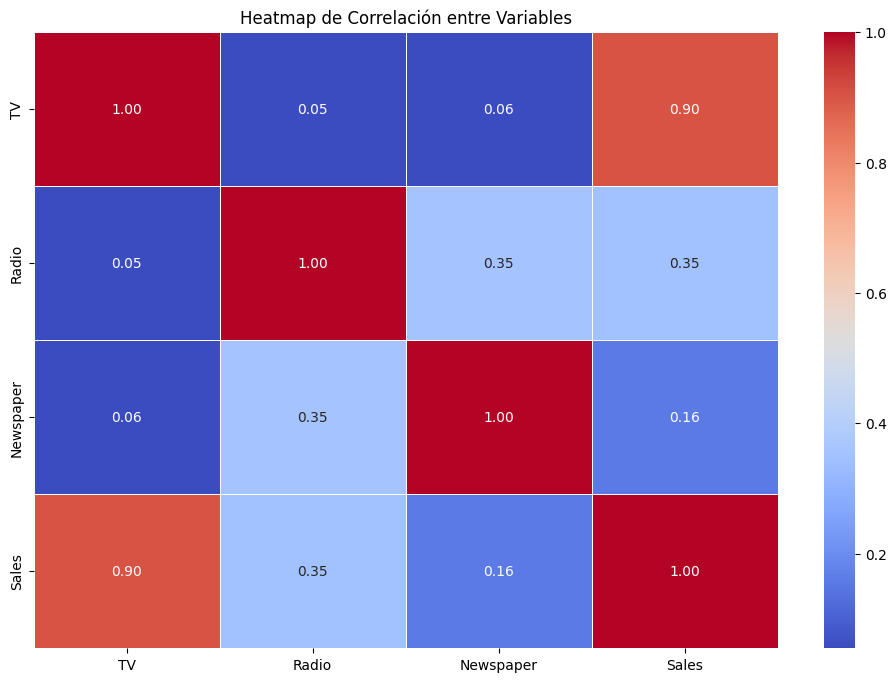

In [23]:
# Correlación y heatmap
#Heatmap de correlación entre todas las variables
plt.figure(figsize=(12, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title("Heatmap de Correlación entre Variables")
plt.show()



¿Qué variables están más correlacionadas con Sales? ¿Hay correlación alta entre predictores?
**Respuesta: TV presenta la correlación más alta con Sales (0.90), seguida de Radio (0.35) y Newspaper (0.16). Entre las variables independientes no se observan correlaciones altas: la mayor es la de Radio y Newspaper (0.35), por lo que no hay indicios de multicolinealidad**

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?


### Análisis de Multicolinealidad ###
    Variable       VIF
0      const  1.000000
1         TV  1.004611
2      Radio  1.144952
3  Newspaper  1.145187


/tmp/ipykernel_886/1956636473.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')


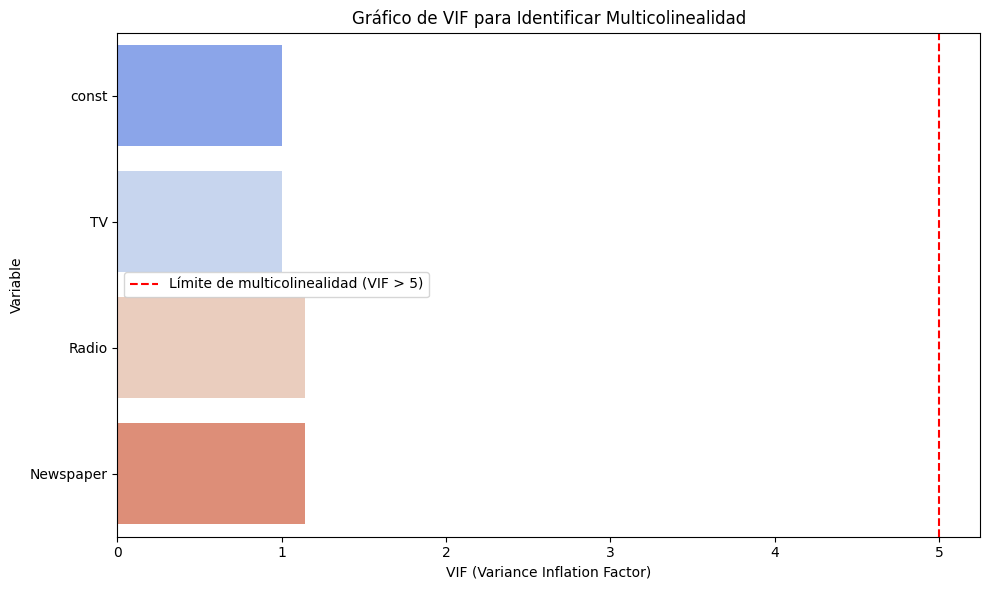

In [25]:
#Multicolinealidad

# Multicolinealidad: Cálculo de VIF (Variance Inflation Factor)
# El VIF evalúa la colinealidad de cada variable con respecto a las demás. VIF > 5 o 10 indica posible multicolinealidad.

# Agregar constante para calcular el VIF
X = add_constant(df.drop(columns=['Sales']))  # Matriz de características sin la variable dependiente
vif_data = pd.DataFrame()
vif_data['Variable'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print("\n### Análisis de Multicolinealidad ###")
print(vif_data)

# Visualización de VIF
plt.figure(figsize=(10, 6))
sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')
plt.axvline(x=5, color='red', linestyle='--', label='Límite de multicolinealidad (VIF > 5)')
plt.xlabel('VIF (Variance Inflation Factor)')
plt.title('Gráfico de VIF para Identificar Multicolinealidad')
plt.legend()
plt.tight_layout()
plt.show()


3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?
**Ninguna de las variables independientes presenta un VIF mayor a 5 ni a 10 (TV = 1.00, Radio = 1.14, Newspaper = 1.15), por lo que se descarta la presencia de multicolinealidad. Esto implica que los coeficientes del modelo son estables y pueden interpretarse de forma individual sin necesidad de aplicar técnicas de corrección.**

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [26]:
#ntrenamiento del Modelo (Todas las Variables Independientes)

# Variables independientes (X) y dependiente (y)
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Entrenamiento del modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Intercepto y coeficientes
print("Intercepto:", modelo.intercept_)
print("\nCoeficientes:")
for variable, coef in zip(X.columns, modelo.coef_):
    print(f"  {variable}: {coef:.4f}")

Intercepto: 4.625124078808653

Coeficientes:
  TV: 0.0544
  Radio: 0.1070
  Newspaper: 0.0003


Interpreta cada uno: ¿Qué significa cada uno de los coeficientes en términos de ventas?
**Respuesta: El intercepto (4.62) representa las ventas esperadas sin inversión publicitaria. El coeficiente de TV (0.0544) indica que, manteniendo constantes las demás variables, cada unidad adicional invertida en TV incrementa las ventas en 0.0544 unidades. El de Radio (0.1070) señala un incremento de 0.1070 unidades por cada unidad invertida, el mayor retorno por unidad entre los tres medios. El de Newspaper (0.0003) es prácticamente nulo, por lo que este medio no contribuye de manera relevante a las ventas una vez controlado el efecto de TV y Radio.**

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LinearRegression()
model.fit(X_scaled,y)

LinearRegression()

0      0.879028
1     -0.868248
2      1.503791
3     -0.812447
4      2.255863
         ...   
195    0.494510
196    3.719059
197   -0.459287
198    0.917780
199    0.214880
Name: Sales, Length: 200, dtype: float64


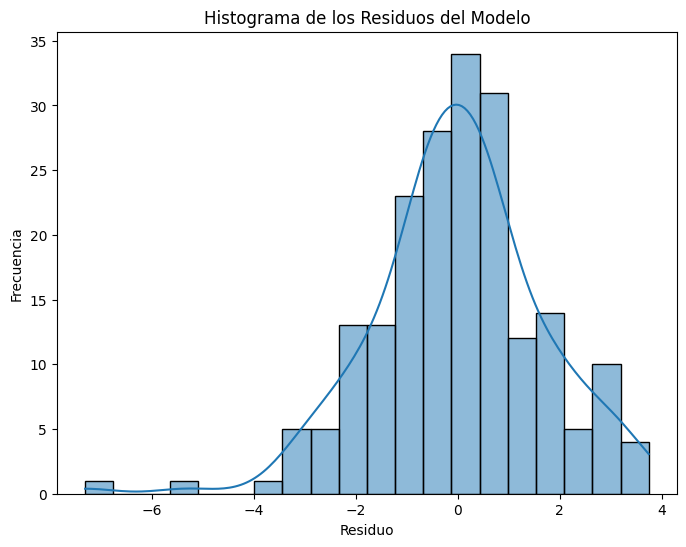

In [27]:
y_pred = model.predict(X_scaled)

# Calcular los residuos del modelo
residuos = y - y_pred
print(residuos)

# Graficar el histograma de los residuos
plt.figure(figsize=(8, 6))
sns.histplot(residuos, bins=20, kde=True)
plt.title("Histograma de los Residuos del Modelo")
plt.xlabel("Residuo")
plt.ylabel("Frecuencia")
plt.show()

3. ¿Los residuos parecen distribuirse normalmente? Respuesta: **El histograma de los residuos muestra una distribución aproximadamente simétrica y centrada en cero, con forma de campana. Sin embargo, se observa una cola izquierda más larga, con algunos residuos extremos (cercanos a -7), lo que indica una ligera asimetría negativa y posibles valores atípicos. En conjunto, el supuesto de normalidad se cumple de forma aproximada, aunque no es perfecta.**


### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

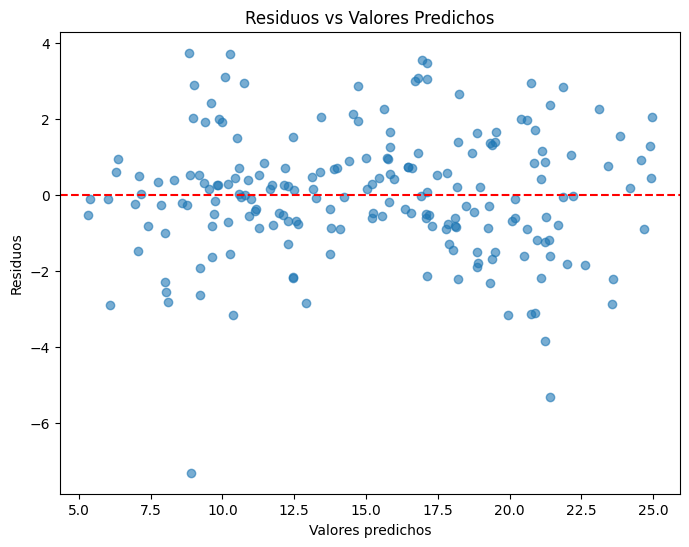

In [28]:
# Calcular los residuos del modelo
residuos = y - y_pred

# Graficar residuos vs valores predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuos, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')   # línea de referencia en 0
plt.title("Residuos vs Valores Predichos")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.show()

¿Observas patrones? ¿Los residuos se dispersan aleatoriamente? Respuesta: **El gráfico de residuos vs valores predichos muestra que los residuos se distribuyen alrededor de cero sin un patrón de embudo claro, lo que sugiere homocedasticidad aproximada. No obstante, se aprecia una ligera curvatura y dos valores atípicos con residuos negativos marcados (cercanos a -7 y -5), lo que indica que la relación lineal no captura por completo el comportamiento de las ventas. Esto sugiere que el modelo podría mejorarse**

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

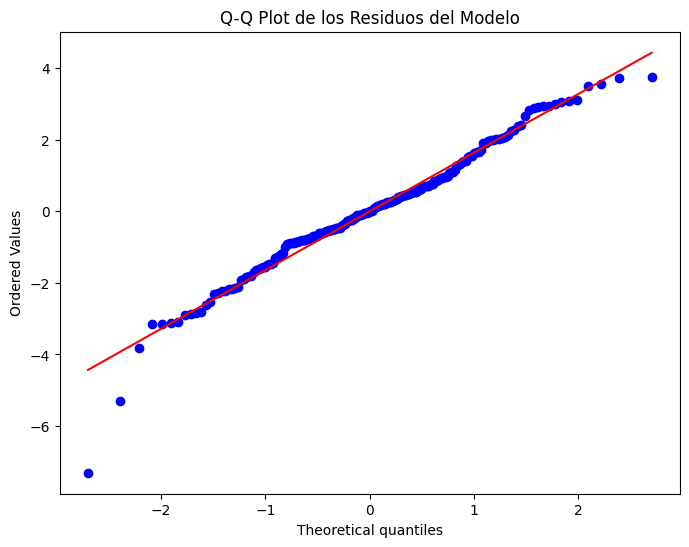

In [29]:
#Q-Q Plot

import scipy.stats as stats

# Calcular los residuos del modelo
residuos = y - y_pred

# Graficar el Q-Q Plot
plt.figure(figsize=(8, 6))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q Plot de los Residuos del Modelo")
plt.show()

2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.
Respuesta: **En el Q-Q plot, los puntos se alinean aproximadamente sobre la diagonal en la región central, lo que indica que los residuos siguen una distribución cercana a la normal. Sin embargo, en el extremo inferior se observan desviaciones sistemáticas, con algunos residuos considerablemente más negativos de lo esperado, lo que evidencia una cola izquierda pesada y una ligera asimetría negativa. Esto sugiere la presencia de valores atípicos, aunque el supuesto de normalidad se cumple de manera aproximada para la mayor parte de las observaciones**


### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [30]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Calcular las métricas del modelo
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
mae = mean_absolute_error(y, y_pred)  # Error absoluto medio
r2 = r2_score(y, y_pred)  # Coeficiente de determinación R^2

# y mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")


Error Cuadrático Medio (MSE): 2.7060
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Error Absoluto Medio (MAE): 1.2364
Coeficiente de Determinación (R²): 0.9026


**El modelo presenta un buen ajuste ya que el R² de 0.9026 indica que explica aproximadamente el 90% de la variabilidad de las ventas. El RMSE (1.645) y el MAE (1.236) muestran que, en promedio, las predicciones se desvían entre 1.2 y 1.6 unidades del valor real, un error moderado en relación con el rango de la variable. La diferencia entre RMSE y MAE sugiere la presencia de algunos errores grandes asociados a los valores atípicos identificados en los residuos. En conjunto, esto demuestra que el modelo es adecuado para describir y predecir las ventas, aunque podría mejorarse.**

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

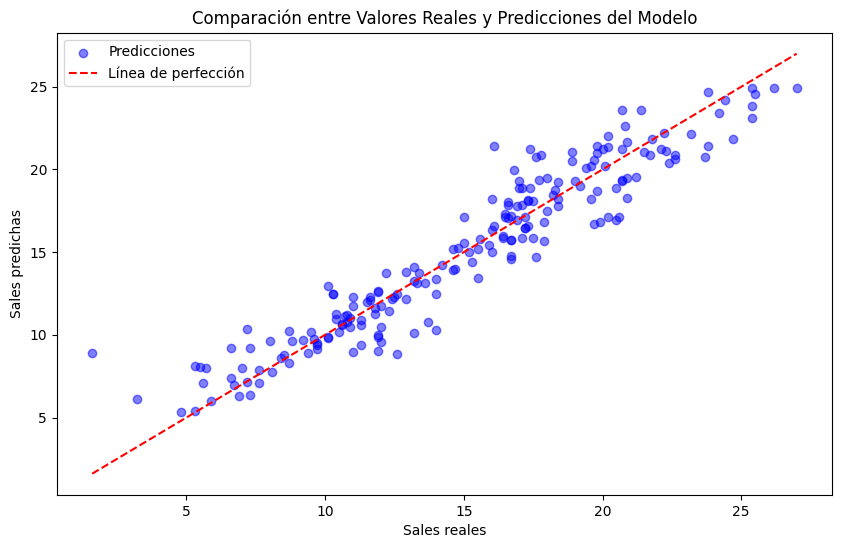


Comparación entre las predicciones y los valores reales:
   Valor Real  Predicción
0        22.1   21.220972
1        10.4   11.268248
2        12.0   10.496209
3        16.5   17.312447
4        17.9   15.644137


In [31]:
#Visualización de las Predicciones

#Realizar predicciones con el modelo
y_pred = model.predict(X_scaled)

# Graficar los valores reales frente a las predicciones
plt.figure(figsize=(10, 6))

# Graficar los valores reales vs las predicciones
plt.scatter(y, y_pred, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')
plt.title("Comparación entre Valores Reales y Predicciones del Modelo")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.legend()
plt.show()

# Comparar los primeros valores reales con las predicciones
comparison = pd.DataFrame({
    'Valor Real': y.head(),
    'Predicción': y_pred[:5]  # Primeras 5 predicciones
})

print("\nComparación entre las predicciones y los valores reales:")
print(comparison)

3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?
**El gráfico de valores reales vs predichos muestra que los puntos se distribuyen de forma cercana a la línea de perfección, lo que confirma el buen ajuste del modelo (R² = 0.90). La dispersión es moderada y consistente con el RMSE obtenido. Se observan algunas desviaciones, principalmente un valor atípico con sobreestimación marcada (venta real cercana a 1.6 y predicción cercana a 9) y una ligera tendencia a sobreestimar las ventas bajas y subestimar las altas, lo que sugiere una leve no linealidad. En conjunto, el modelo es adecuado para predecir las ventas, aunque podría mejorarse incorporando términos no lineales o interacciones.**

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [32]:
import statsmodels.api as sm

# Agregar una constante al conjunto de datos X_scaled
X_scaled_with_constant = sm.add_constant(X_scaled)

# Ajustar el modelo de regresión lineal utilizando statsmodels
model_sm = sm.OLS(y, X_scaled_with_constant).fit()

print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           8.13e-99
Time:                        23:49:55   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.1305      0.117    128.771      0.0

Interpreta los resultados:
Observa los valores P>|t| en la tabla de salida.

¿Qué variables tienen p-value menores a 0.05?

¿Cuál es la conclusión sobre esas variables?

**Los resultados del modelo OLS muestran que TV (p < 0.001) y Radio (p < 0.001) tienen un efecto estadísticamente significativo sobre las ventas, al ser sus p-values menores a 0.05 y sus intervalos de confianza no incluir el cero. Por otro lado, Newspaper no es significativa (p = 0.954), por lo que no hay evidencia de que contribuya a explicar las ventas una vez controlado el efecto de TV y Radio. Se concluye que la inversión en TV y Radio es la que impulsa las ventas, siendo TV la de mayor influencia.**

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**Respuesta = No se identifica multicolinealidad entre las variables independientes. Los valores de VIF (TV = 1.00, Radio = 1.14, Newspaper = 1.15) son cercanos a 1 y se encuentran muy por debajo del umbral de 5, lo que indica que cada predictor aporta información independiente y que los coeficientes estimados son estables y confiables para su interpretación.**

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [33]:

##Se quita variable Newspaper ya que no se encontró relación lineal y se realiza nuevamente la Parte 4 con las 2 variables restantes

X2 = df[['TV', 'Radio']]
y = df['Sales']

modelo2 = LinearRegression()
modelo2.fit(X2, y)

print("Intercepto:", modelo2.intercept_)
print("\nCoeficientes:")
for variable, coef in zip(X2.columns, modelo2.coef_):
    print(f"  {variable}: {coef:.4f}")

Intercepto: 4.630879464097768

Coeficientes:
  TV: 0.0544
  Radio: 0.1072


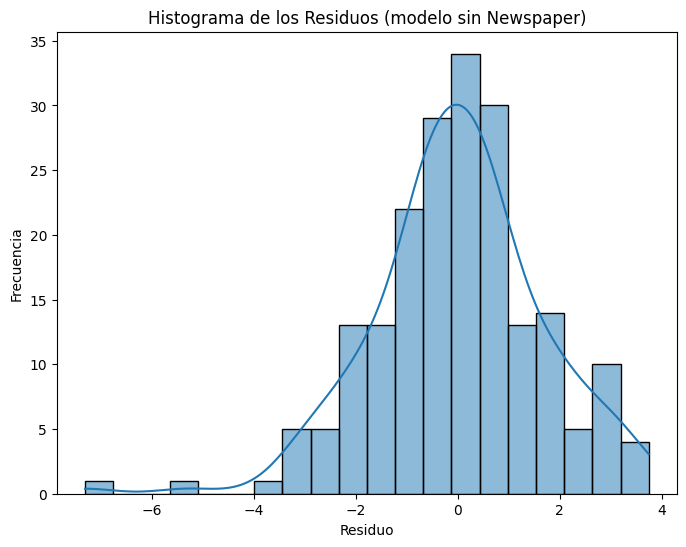

In [34]:

##Normalidad de los residuos##
y_pred2 = modelo2.predict(X2)
residuos2 = y - y_pred2

plt.figure(figsize=(8, 6))
sns.histplot(residuos2, bins=20, kde=True)
plt.title("Histograma de los Residuos (modelo sin Newspaper)")
plt.xlabel("Residuo")
plt.ylabel("Frecuencia")
plt.show()

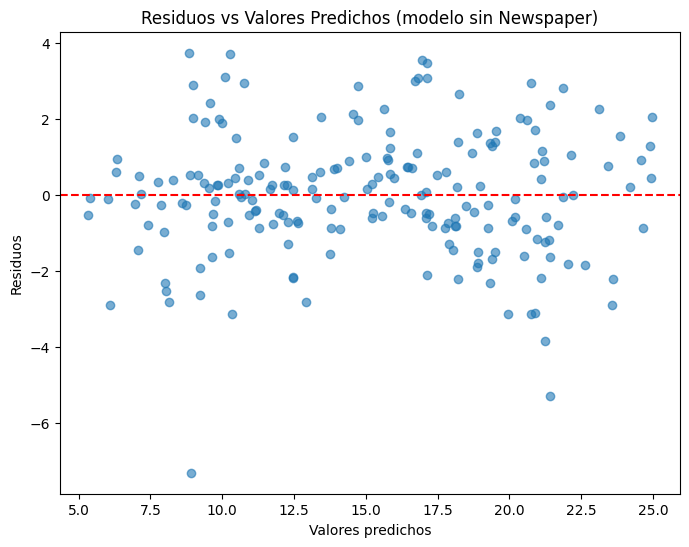

In [35]:

##Homocedasticidad##
plt.figure(figsize=(8, 6))
plt.scatter(y_pred2, residuos2, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')
plt.title("Residuos vs Valores Predichos (modelo sin Newspaper)")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.show()

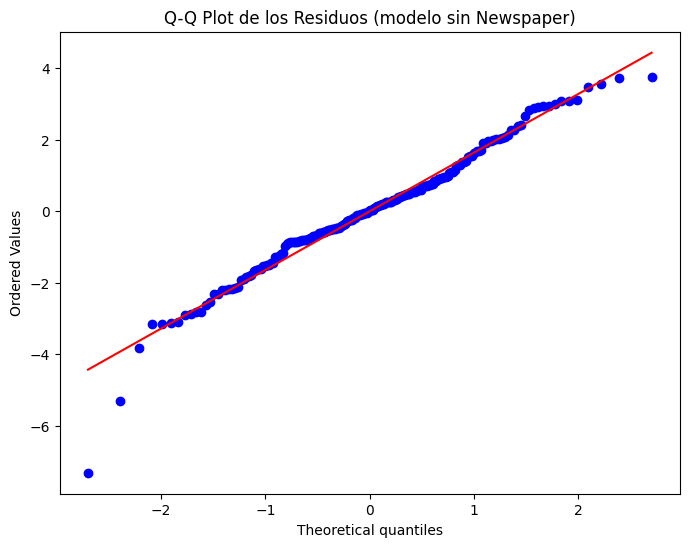

In [36]:
##Q-Q Plot##

plt.figure(figsize=(8, 6))
stats.probplot(residuos2, dist="norm", plot=plt)
plt.title("Q-Q Plot de los Residuos (modelo sin Newspaper)")
plt.show()

In [37]:
##Evaluación del modelo##

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse2 = mean_squared_error(y, y_pred2)
rmse2 = np.sqrt(mse2)
mae2 = mean_absolute_error(y, y_pred2)
r2_2 = r2_score(y, y_pred2)

print(f"MSE:  {mse2:.4f}")
print(f"RMSE: {rmse2:.4f}")
print(f"MAE:  {mae2:.4f}")
print(f"R²:   {r2_2:.4f}")

MSE:  2.7061
RMSE: 1.6450
MAE:  1.2368
R²:   0.9026


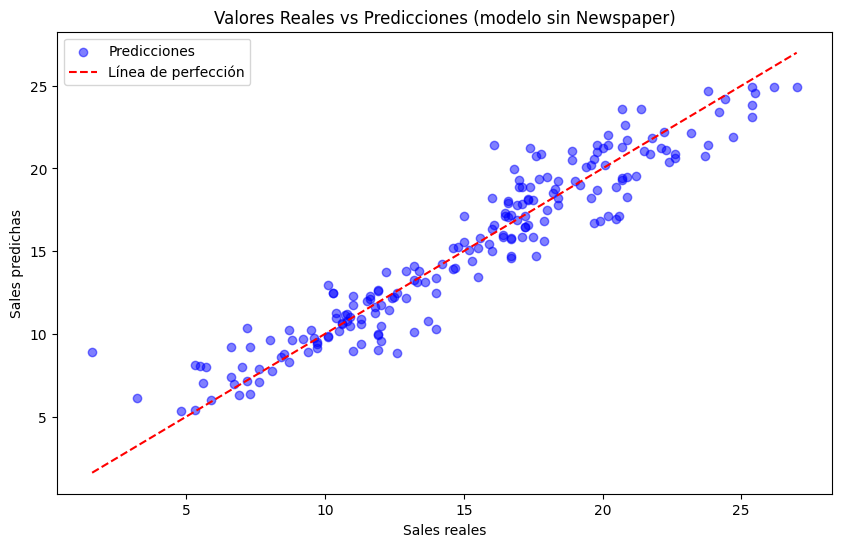

In [38]:
##Valores reales vs predichos##

plt.figure(figsize=(10, 6))
plt.scatter(y, y_pred2, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')
plt.title("Valores Reales vs Predicciones (modelo sin Newspaper)")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.legend()
plt.show()

In [39]:

X2_const = sm.add_constant(X2)
modelo2_sm = sm.OLS(y, X2_const).fit()
print(modelo2_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Tue, 03 Nov 2026   Prob (F-statistic):          2.39e-100
Time:                        23:51:54   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

**Al eliminar Newspaper, el modelo con TV y Radio no pierde capacidad explicativa ni predictiva: el R² (0.9026), el RMSE (1.645) y los coeficientes son prácticamente iguales a los del modelo completo. Las diferencias aparecen solo en los criterios que penalizan la complejidad: R² ajustado ligeramente mayor, AIC y BIC más bajos y un estadístico F más alto (912.7 frente a 605.4). Esto confirma que Newspaper no aportaba información útil y que el modelo reducido es preferible. Los supuestos se comportan igual que antes en donde se ve la normalidad aproximada con cola izquierda pesada, homocedasticidad razonable y una ligera no linealidad asociada a TV. Esas limitaciones no dependen de Newspaper**

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

**El mejor modelo es el de la Parte 6 (TV y Radio): iguala el ajuste del modelo completo con menos variables y mejores criterios de información. El atributo con mayor influencia en las ventas es TV: tiene la correlación más alta con Sales (0.90) y el mayor coeficiente estandarizado (4.66 frente a 1.58 de Radio). Radio tiene el mayor retorno por unidad invertida (0.1072 frente a 0.0544), pero explica menos variación total.**